In [1]:
import random
import os
os.environ["CUDA_LAUNCH_BLOCKING"] = "1"

import torch
import time
import json
import copy

import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, utils

from torch.utils.data import DataLoader, random_split, ConcatDataset

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

BATCH_SIZE = 128
LATENT_DIM = 64
EPOCHS_AE = 5
EPOCHS_GAN = 5
EPOCHS_DDPM = 5

DATA_DIR = "./data"
OUTPUT_DIR = "./outputs"

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("PyTorch:", torch.__version__)
print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")


PyTorch: 2.14.1+cu130
Device: cuda
GPU: NVIDIA GeForce RTX 2050
VRAM: 4.0 GB


In [2]:

transform = transforms.ToTensor()

full_train = datasets.FashionMNIST(
    root=DATA_DIR,
    train=True,
    download=True,
    transform=transform
)

train_dataset, val_dataset, test_dataset = random_split(
    full_train,
    [48000, 6000, 6000],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

classes = full_train.classes

print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print(
    "Total:",
    len(train_dataset) + len(val_dataset) + len(test_dataset)
)


Train: 48000
Validation: 6000
Test: 6000
Total: 60000


Image batch: torch.Size([128, 1, 28, 28])
Label batch: torch.Size([128])
Pixel range: 0.0 1.0


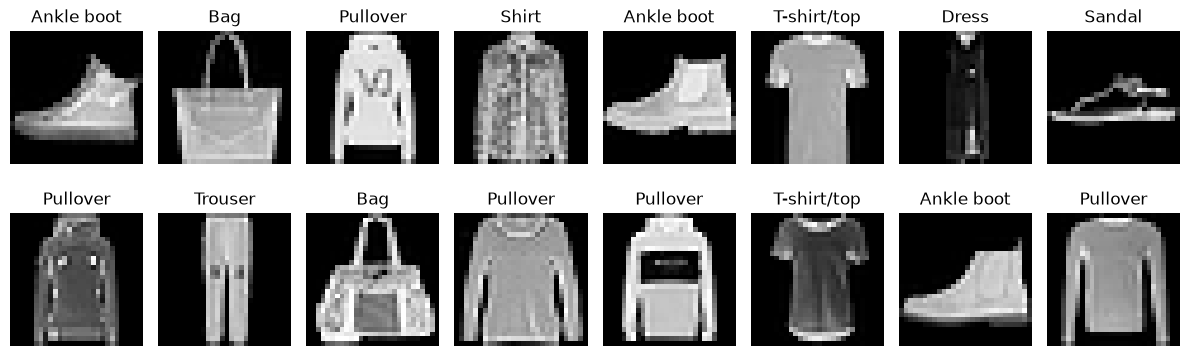

In [3]:
images, labels = next(iter(train_loader))

print("Image batch:", images.shape)
print("Label batch:", labels.shape)
print("Pixel range:", images.min().item(), images.max().item())

fig, axes = plt.subplots(2, 8, figsize=(12, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(classes[labels[i].item()])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:
class VanillaAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)


class SparseAE(VanillaAE):
    def __init__(self, latent_dim=64):
        super().__init__(latent_dim=latent_dim)

    def loss_function(self, recon, x, z, sparsity_lambda=1e-4):
        reconstruction_loss = F.mse_loss(recon, x)
        sparsity_loss = z.abs().mean()
        total_loss = reconstruction_loss + sparsity_lambda * sparsity_loss

        return total_loss, reconstruction_loss, sparsity_loss


class VAE(nn.Module):
    def __init__(self, latent_dim=64):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(256, latent_dim)
        self.fc_logvar = nn.Linear(256, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, mu, logvar




In [5]:
def train_ae_epoch(model, loader, optimizer, sparse=False,
                   sparsity_lambda=1e-4):
    model.train()
    total_loss = 0.0
    total_recon = 0.0

    for x, _ in loader:
        x = x.to(device)
        optimizer.zero_grad()

        z = model.encode(x)
        recon = model.decode(z)

        if sparse:
            loss, recon_loss, _ = model.loss_function(
                recon, x, z, sparsity_lambda
            )
        else:
            recon_loss = F.mse_loss(recon, x)
            loss = recon_loss

        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total_recon += recon_loss.item() * x.size(0)

    n = len(loader.dataset)
    return total_loss / n, total_recon / n


def train_vae_epoch(model, loader, optimizer, beta=1.0):
    model.train()
    total_loss = 0.0
    total_recon = 0.0
    total_kl = 0.0

    for x, _ in loader:
        x = x.to(device)
        optimizer.zero_grad()

        recon, mu, logvar = model(x)

        print("x range:", x.min().item(), x.max().item())
        print("recon range:", recon.min().item(), recon.max().item())
        print("x finite:", torch.isfinite(x).all().item())
        print("recon finite:", torch.isfinite(recon).all().item())
        print("x shape:", x.shape)
        print("recon shape:", recon.shape)

        assert torch.isfinite(x).all(), "x mengandung NaN/Inf"
        assert torch.isfinite(recon).all(), "recon mengandung NaN/Inf"
        assert x.min().item() >= 0 and x.max().item() <= 1, "Target x di luar [0,1]"
        assert recon.min().item() >= 0 and recon.max().item() <= 1, "Output recon di luar [0,1]"

        recon_loss = F.binary_cross_entropy(
            recon, x, reduction="sum"
        ) / x.size(0)

        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        ) / x.size(0)

        loss = recon_loss + beta * kl_loss
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * x.size(0)
        total_recon += recon_loss.item() * x.size(0)
        total_kl += kl_loss.item() * x.size(0)

    n = len(loader.dataset)
    return (
        total_loss / n,
        total_recon / n,
        total_kl / n
    )


@torch.no_grad()
def evaluate_ae(model, loader):
    model.eval()
    total_mse = 0.0
    n = 0

    for x, _ in loader:
        x = x.to(device)
        recon = model(x)
        total_mse += F.mse_loss(
            recon, x, reduction="sum"
        ).item()
        n += x.size(0)

    return total_mse / (n * 784)


@torch.no_grad()
def evaluate_vae(model, loader):
    model.eval()
    total_mse = 0.0
    n = 0

    for x, _ in loader:
        x = x.to(device)
        recon, _, _ = model(x)

        total_mse += F.mse_loss(
            recon, x, reduction="sum"
        ).item()
        n += x.size(0)

    return total_mse / (n * 784)



## Model & Training Vanilla AE, Sparse AE, VAE

In [6]:
models = {
    "Vanilla AE": VanillaAE(LATENT_DIM).to(device),
    "Sparse AE": SparseAE(LATENT_DIM).to(device),
    "VAE": VAE(LATENT_DIM).to(device)
}

optimizers = {
    name: torch.optim.Adam(model.parameters(), lr=1e-3)
    for name, model in models.items()
}

history = {
    name: {"train_loss": [], "val_mse": []}
    for name in models
}

for name, model in models.items():
    print(f"\nTraining {name}...")
    start = time.time()

    for epoch in range(EPOCHS_AE):
        if name == "VAE":
            train_loss, recon_loss, kl_loss = train_vae_epoch(
                model, train_loader, optimizers[name]
            )
            print(
                f"Epoch {epoch+1}/{EPOCHS_AE} | "
                f"Loss: {train_loss:.4f} | "
                f"Recon: {recon_loss:.4f} | KL: {kl_loss:.4f}"
            )
        else:
            train_loss, recon_loss = train_ae_epoch(
                model,
                train_loader,
                optimizers[name],
                sparse=(name == "Sparse AE")
            )
            print(
                f"Epoch {epoch+1}/{EPOCHS_AE} | "
                f"Loss: {train_loss:.6f} | "
                f"Recon: {recon_loss:.6f}"
            )

        history[name]["train_loss"].append(train_loss)
        val_mse = (
            evaluate_vae(model, val_loader)
            if name == "VAE"
            else evaluate_ae(model, val_loader)
        )
        history[name]["val_mse"].append(val_mse)

    elapsed = time.time() - start
    print(f"{name} training time: {elapsed:.1f}s")
    torch.save(model.state_dict(),
               f"{OUTPUT_DIR}/{name.lower().replace(' ', '_')}.pth")




Training Vanilla AE...
Epoch 1/5 | Loss: 0.034671 | Recon: 0.034671
Epoch 2/5 | Loss: 0.017421 | Recon: 0.017421
Epoch 3/5 | Loss: 0.014711 | Recon: 0.014711
Epoch 4/5 | Loss: 0.013111 | Recon: 0.013111
Epoch 5/5 | Loss: 0.011947 | Recon: 0.011947
Vanilla AE training time: 65.2s

Training Sparse AE...
Epoch 1/5 | Loss: 0.034801 | Recon: 0.034629
Epoch 2/5 | Loss: 0.017682 | Recon: 0.017530
Epoch 3/5 | Loss: 0.014873 | Recon: 0.014734
Epoch 4/5 | Loss: 0.013121 | Recon: 0.012990
Epoch 5/5 | Loss: 0.012062 | Recon: 0.011937
Sparse AE training time: 69.8s

Training VAE...
x range: 0.0 1.0
recon range: 0.25411880016326904 0.7441220879554749
x finite: True
recon finite: True
x shape: torch.Size([128, 1, 28, 28])
recon shape: torch.Size([128, 1, 28, 28])
x range: 0.0 1.0
recon range: 0.19443446397781372 0.7273674607276917
x finite: True
recon finite: True
x shape: torch.Size([128, 1, 28, 28])
recon shape: torch.Size([128, 1, 28, 28])
x range: 0.0 1.0
recon range: 0.21610590815544128 0.73538

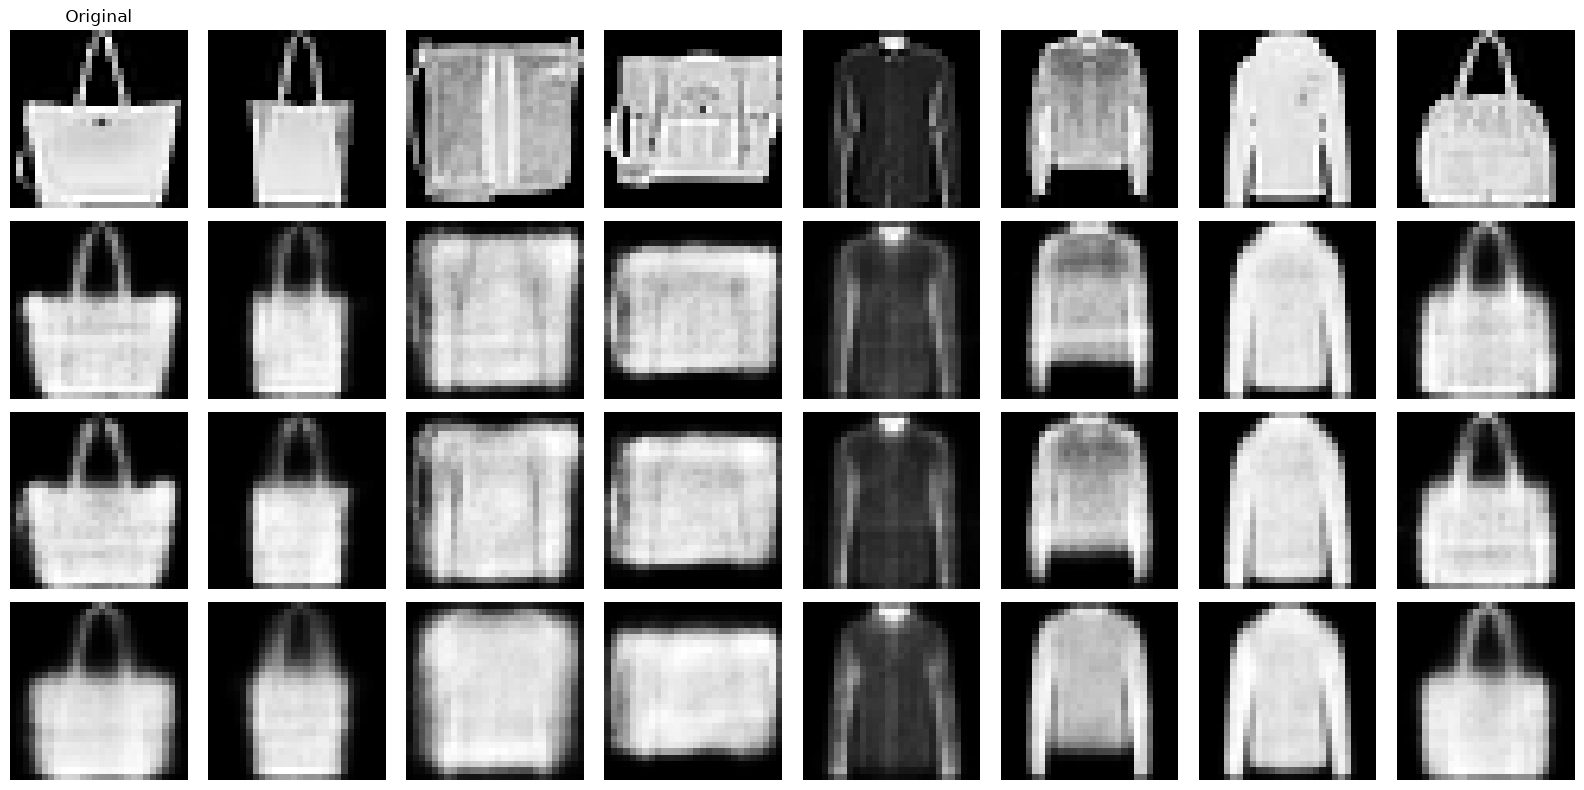

In [7]:
@torch.no_grad()
def show_reconstructions(models, loader, n=8):
    x, _ = next(iter(loader))
    x = x[:n].to(device)

    fig, axes = plt.subplots(
        len(models) + 1,
        n,
        figsize=(2 * n, 2 * (len(models) + 1))
    )

    for j in range(n):
        axes[0, j].imshow(x[j, 0].cpu(), cmap="gray")
        axes[0, j].axis("off")
        axes[0, j].set_title("Original" if j == 0 else "")

    for i, (name, model) in enumerate(models.items(), start=1):
        model.eval()

        if isinstance(model, VAE):
            recon, _, _ = model(x)
        else:
            recon = model(x)

        for j in range(n):
            axes[i, j].imshow(
                recon[j, 0].cpu().clamp(0, 1),
                cmap="gray"
            )
            axes[i, j].axis("off")

        axes[i, 0].set_ylabel(
            name, rotation=90, size=10
        )

    plt.tight_layout()
    plt.savefig(
        f"{OUTPUT_DIR}/figure1_reconstructions.png",
        dpi=200,
        bbox_inches="tight"
    )
    plt.show()


show_reconstructions(models, test_loader)

## Model & Training Vanilla GAN

In [8]:

class Generator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(noise_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 512),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.3),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


NOISE_DIM = 100
gan_G = Generator(NOISE_DIM).to(device)
gan_D = Discriminator().to(device)

gan_loss_fn = nn.BCELoss()
gan_opt_G = torch.optim.Adam(gan_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
gan_opt_D = torch.optim.Adam(gan_D.parameters(), lr=2e-4, betas=(0.5, 0.999))

gan_history = {"G": [], "D": []}
fixed_noise = torch.randn(64, NOISE_DIM, device=device)

start_time = time.time()

for epoch in range(EPOCHS_GAN):
    gan_G.train()
    gan_D.train()
    total_g, total_d, batches = 0, 0, 0

    for real, _ in train_loader:
        real = real.to(device)
        bs = real.size(0)
        real_labels = torch.ones(bs, 1, device=device)
        fake_labels = torch.zeros(bs, 1, device=device)

        # Train discriminator
        gan_opt_D.zero_grad()
        real_pred = gan_D(real)
        loss_real = gan_loss_fn(real_pred, real_labels)

        noise = torch.randn(bs, NOISE_DIM, device=device)
        fake = gan_G(noise)
        fake_pred = gan_D(fake.detach())
        loss_fake = gan_loss_fn(fake_pred, fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        gan_opt_D.step()

        # Train generator
        gan_opt_G.zero_grad()
        noise = torch.randn(bs, NOISE_DIM, device=device)
        generated = gan_G(noise)
        pred = gan_D(generated)
        loss_g = gan_loss_fn(pred, real_labels)
        loss_g.backward()
        gan_opt_G.step()

        total_g += loss_g.item()
        total_d += loss_d.item()
        batches += 1

    gan_history["G"].append(total_g / batches)
    gan_history["D"].append(total_d / batches)
    print(
        f"Vanilla GAN Epoch {epoch+1}/{EPOCHS_GAN} | "
        f"G: {gan_history['G'][-1]:.4f} | "
        f"D: {gan_history['D'][-1]:.4f}"
    )

print(f"Vanilla GAN training time: {(time.time()-start_time)/60:.2f} minutes")
torch.save(gan_G.state_dict(), f"{OUTPUT_DIR}/vanilla_gan_generator.pth")
torch.save(gan_D.state_dict(), f"{OUTPUT_DIR}/vanilla_gan_discriminator.pth")


Vanilla GAN Epoch 1/5 | G: 2.5784 | D: 0.2553
Vanilla GAN Epoch 2/5 | G: 2.4535 | D: 0.2771
Vanilla GAN Epoch 3/5 | G: 2.6304 | D: 0.2947
Vanilla GAN Epoch 4/5 | G: 2.5751 | D: 0.2975
Vanilla GAN Epoch 5/5 | G: 2.0709 | D: 0.3498
Vanilla GAN training time: 1.41 minutes


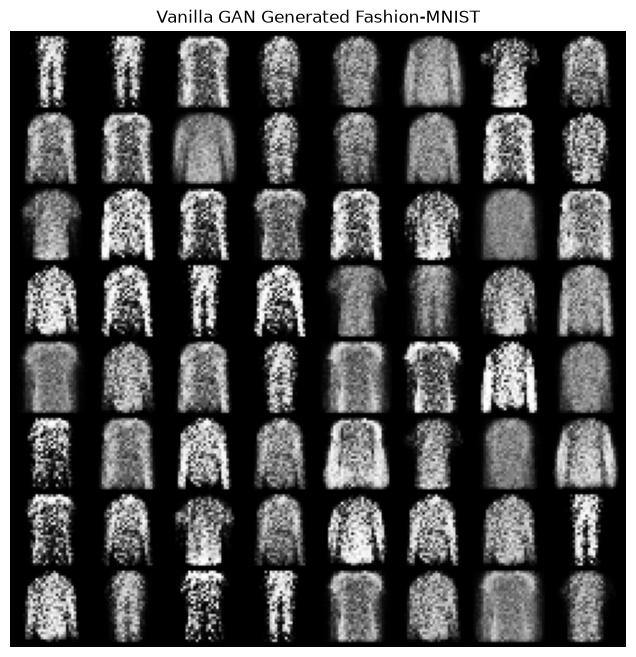

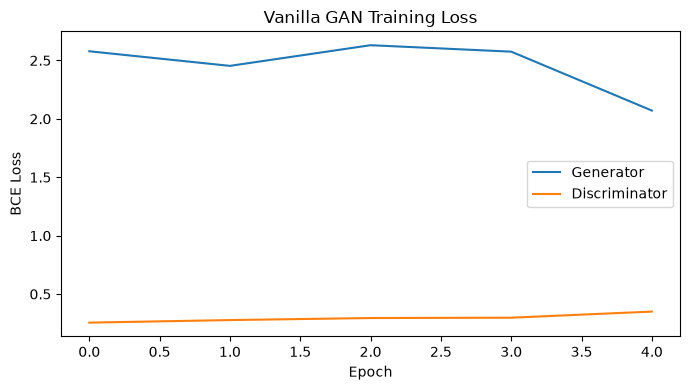

In [9]:
@torch.no_grad()
def show_generated(generator, noise_dim=100, title="Generated Samples",
                   save_path=None, n=64):
    generator.eval()
    z = torch.randn(n, noise_dim, device=device)
    samples = generator(z).cpu()

    grid = utils.make_grid(samples, nrow=8, padding=2)
    plt.figure(figsize=(8, 8))
    plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
    plt.title(title)
    plt.axis("off")
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()

show_generated(
    gan_G,
    title="Vanilla GAN Generated Fashion-MNIST",
    save_path=f"{OUTPUT_DIR}/vanilla_gan_samples.png"
)

plt.figure(figsize=(7, 4))
plt.plot(gan_history["G"], label="Generator")
plt.plot(gan_history["D"], label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("Vanilla GAN Training Loss")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/vanilla_gan_loss.png", dpi=150)
plt.show()


## Model & Training DCGAN

In [10]:

class DCGenerator(nn.Module):
    def __init__(self, noise_dim=100):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(noise_dim, 256, 7, 1, 0, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            nn.ConvTranspose2d(128, 1, 4, 2, 1, bias=False),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z.view(z.size(0), z.size(1), 1, 1))


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.net(x)


dc_G = DCGenerator(NOISE_DIM).to(device)
dc_D = DCDiscriminator().to(device)

dc_loss_fn = nn.BCELoss()
dc_opt_G = torch.optim.Adam(dc_G.parameters(), lr=2e-4, betas=(0.5, 0.999))
dc_opt_D = torch.optim.Adam(dc_D.parameters(), lr=2e-4, betas=(0.5, 0.999))

dc_history = {"G": [], "D": []}
start_time = time.time()

for epoch in range(EPOCHS_GAN):
    dc_G.train()
    dc_D.train()
    total_g, total_d, batches = 0, 0, 0

    for real, _ in train_loader:
        real = real.to(device)
        bs = real.size(0)
        real_labels = torch.ones(bs, 1, device=device)
        fake_labels = torch.zeros(bs, 1, device=device)

        dc_opt_D.zero_grad()
        loss_real = dc_loss_fn(dc_D(real), real_labels)

        z = torch.randn(bs, NOISE_DIM, device=device)
        fake = dc_G(z)
        loss_fake = dc_loss_fn(dc_D(fake.detach()), fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        dc_opt_D.step()

        dc_opt_G.zero_grad()
        z = torch.randn(bs, NOISE_DIM, device=device)
        generated = dc_G(z)
        loss_g = dc_loss_fn(dc_D(generated), real_labels)
        loss_g.backward()
        dc_opt_G.step()

        total_g += loss_g.item()
        total_d += loss_d.item()
        batches += 1

    dc_history["G"].append(total_g / batches)
    dc_history["D"].append(total_d / batches)
    print(
        f"DCGAN Epoch {epoch+1}/{EPOCHS_GAN} | "
        f"G: {dc_history['G'][-1]:.4f} | "
        f"D: {dc_history['D'][-1]:.4f}"
    )

print(f"DCGAN training time: {(time.time()-start_time)/60:.2f} minutes")
torch.save(dc_G.state_dict(), f"{OUTPUT_DIR}/dcgan_generator.pth")
torch.save(dc_D.state_dict(), f"{OUTPUT_DIR}/dcgan_discriminator.pth")


DCGAN Epoch 1/5 | G: 1.2943 | D: 0.4814
DCGAN Epoch 2/5 | G: 1.0991 | D: 0.5235
DCGAN Epoch 3/5 | G: 0.9885 | D: 0.5742
DCGAN Epoch 4/5 | G: 0.9321 | D: 0.5976
DCGAN Epoch 5/5 | G: 0.9269 | D: 0.6043
DCGAN training time: 2.78 minutes


In [11]:
@torch.no_grad()
def show_generated(generator, title="Generated Samples",
                   save_path=None, n=16):
    generator.eval()

    z_dim = getattr(generator, "latent_dim", 100)
    z = torch.randn(n, z_dim, device=device)
    samples = generator(z).detach().cpu()

    # Jika output generator berbentuk [N, 784],
    # ubah menjadi gambar grayscale 28x28.
    if samples.ndim == 2 and samples.shape[1] == 784:
        samples = samples.view(-1, 1, 28, 28)

    # Hasilkan grid gambar.
    cols = 4
    rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(
        rows, cols, figsize=(8, 2 * rows)
    )
    axes = np.array(axes).reshape(-1)

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < min(n, len(samples)):
            img = samples[i]
            if img.ndim == 3 and img.shape[0] == 1:
                img = img[0]
            ax.imshow(img, cmap="gray")

    fig.suptitle(title)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()

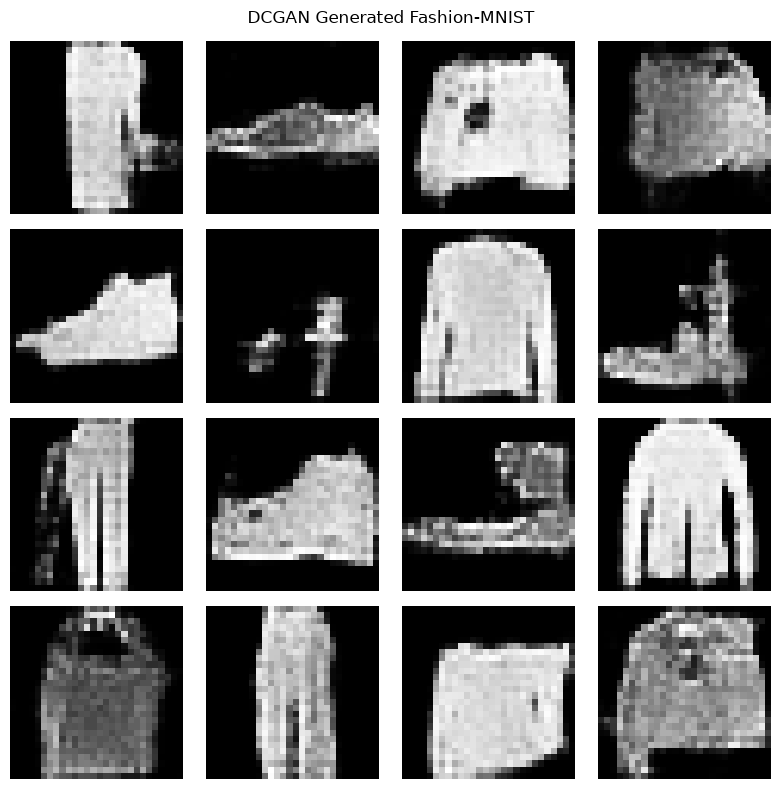

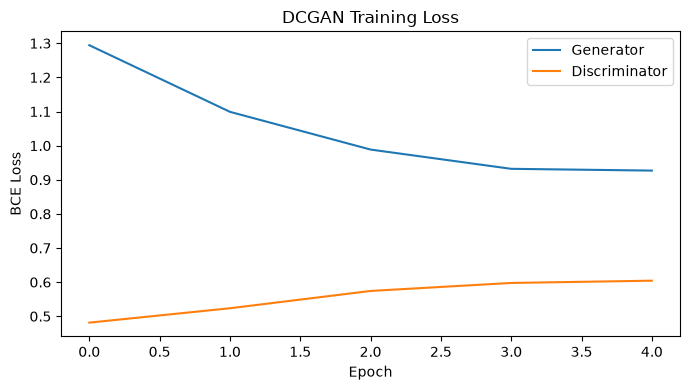

In [12]:

show_generated(
    dc_G,
    title="DCGAN Generated Fashion-MNIST",
    save_path=f"{OUTPUT_DIR}/dcgan_samples.png"
)

plt.figure(figsize=(7, 4))
plt.plot(dc_history["G"], label="Generator")
plt.plot(dc_history["D"], label="Discriminator")
plt.xlabel("Epoch")
plt.ylabel("BCE Loss")
plt.title("DCGAN Training Loss")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/dcgan_loss.png", dpi=150)
plt.show()


## Model & Training DDPM

In [13]:

DIFFUSION_STEPS = 100
TIME_EMBED_DIM = 32

betas = torch.linspace(1e-4, 0.02, DIFFUSION_STEPS, device=device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)


class Denoiser(nn.Module):
    def __init__(self, time_dim=TIME_EMBED_DIM):
        super().__init__()
        self.time_embed = nn.Embedding(DIFFUSION_STEPS, time_dim)
        self.net = nn.Sequential(
            nn.Linear(784 + time_dim, 512),
            nn.GELU(),
            nn.Linear(512, 512),
            nn.GELU(),
            nn.Linear(512, 784)
        )

    def forward(self, x, t):
        x = x.view(x.size(0), -1)
        t_emb = self.time_embed(t)
        return self.net(torch.cat([x, t_emb], dim=1))


ddpm = Denoiser().to(device)
ddpm_optimizer = torch.optim.Adam(ddpm.parameters(), lr=1e-3)
ddpm_history = []
start_time = time.time()

for epoch in range(EPOCHS_DDPM):
    ddpm.train()
    running_loss, batches = 0, 0

    for x, _ in train_loader:
        x = x.to(device)
        bs = x.size(0)

        t = torch.randint(0, DIFFUSION_STEPS, (bs,), device=device)
        noise = torch.randn_like(x)

        a_bar = alpha_bars[t].view(bs, 1, 1, 1)
        noisy_x = torch.sqrt(a_bar) * x + torch.sqrt(1 - a_bar) * noise

        predicted_noise = ddpm(noisy_x, t)
        noise_flat = noise.view(bs, -1)

        loss = F.mse_loss(predicted_noise, noise_flat)

        ddpm_optimizer.zero_grad()
        loss.backward()
        ddpm_optimizer.step()

        running_loss += loss.item()
        batches += 1

    epoch_loss = running_loss / batches
    ddpm_history.append(epoch_loss)
    print(f"DDPM Epoch {epoch+1}/{EPOCHS_DDPM} | Noise MSE: {epoch_loss:.4f}")

print(f"DDPM training time: {(time.time()-start_time)/60:.2f} minutes")
torch.save(ddpm.state_dict(), f"{OUTPUT_DIR}/ddpm_denoiser.pth")


DDPM Epoch 1/5 | Noise MSE: 0.7914
DDPM Epoch 2/5 | Noise MSE: 0.6348
DDPM Epoch 3/5 | Noise MSE: 0.5834
DDPM Epoch 4/5 | Noise MSE: 0.5587
DDPM Epoch 5/5 | Noise MSE: 0.5425
DDPM training time: 1.18 minutes


In [14]:
print("Diffusion steps:", DIFFUSION_STEPS)
print("First beta:", betas[0].item())
print("Last beta:", betas[-1].item())
print("First alpha_bar:", alpha_bars[0].item())
print("Last alpha_bar:", alpha_bars[-1].item())

print("DDPM parameter device:", next(ddpm.parameters()).device)

with torch.no_grad():
    output = ddpm(
        torch.randn(2, 1, 28, 28, device=device),
        torch.zeros(2, dtype=torch.long, device=device)
    )

print("DDPM output shape:", output.shape)

Diffusion steps: 100
First beta: 9.999999747378752e-05
Last beta: 0.019999999552965164
First alpha_bar: 0.9998999834060669
Last alpha_bar: 0.36356320977211
DDPM parameter device: cuda:0
DDPM output shape: torch.Size([2, 784])


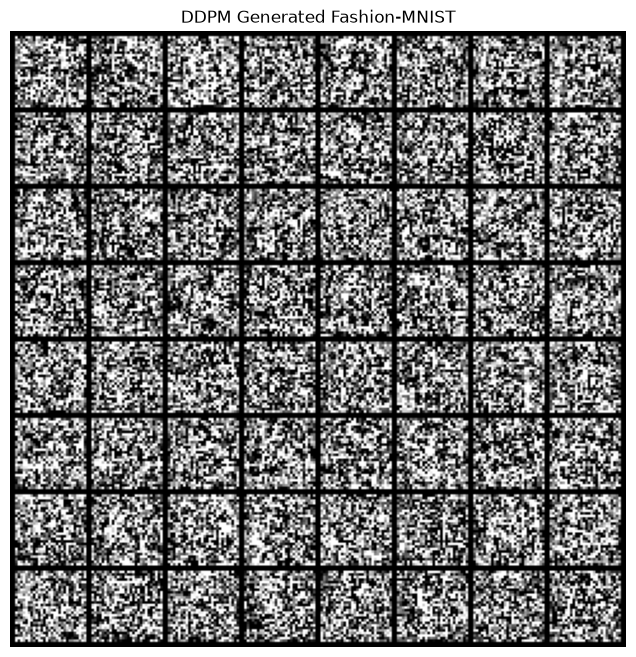

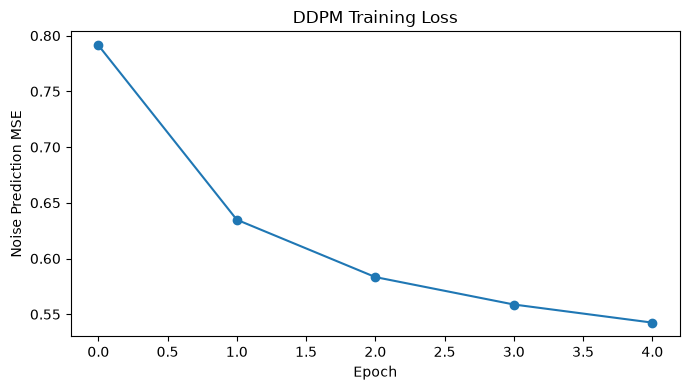

In [15]:
@torch.no_grad()
def sample_ddpm(n=64):
    ddpm.eval()
    x = torch.randn(n, 1, 28, 28, device=device)

    for step in reversed(range(DIFFUSION_STEPS)):
        t = torch.full(
            (n,), step, device=device, dtype=torch.long
        )

        # Model menghasilkan [n, 784], ubah menjadi [n, 1, 28, 28]
        predicted_noise = ddpm(x, t).view_as(x)

        alpha = alphas[step]
        alpha_bar = alpha_bars[step]
        beta = betas[step]

        x = (
            x - (beta / torch.sqrt(1 - alpha_bar)) * predicted_noise
        ) / torch.sqrt(alpha)

        if step > 0:
            noise = torch.randn_like(x)
            x = x + torch.sqrt(beta) * noise

    return ((x.clamp(-1, 1) + 1) / 2)



ddpm_samples = sample_ddpm(64).cpu()
grid = utils.make_grid(ddpm_samples, nrow=8, padding=2)

plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.title("DDPM Generated Fashion-MNIST")
plt.axis("off")
plt.savefig(f"{OUTPUT_DIR}/ddpm_samples.png", dpi=150, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(ddpm_history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Noise Prediction MSE")
plt.title("DDPM Training Loss")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/ddpm_loss.png", dpi=150)
plt.show()


## Training MLP classifier

Epoch 1/10 | Loss: 0.6257 | Val accuracy: 83.75% | Best: 83.75%
Epoch 2/10 | Loss: 0.4247 | Val accuracy: 85.98% | Best: 85.98%
Epoch 3/10 | Loss: 0.3748 | Val accuracy: 86.80% | Best: 86.80%
Epoch 4/10 | Loss: 0.3418 | Val accuracy: 87.55% | Best: 87.55%
Epoch 5/10 | Loss: 0.3220 | Val accuracy: 86.97% | Best: 87.55%
Epoch 6/10 | Loss: 0.3057 | Val accuracy: 88.05% | Best: 88.05%
Epoch 7/10 | Loss: 0.2901 | Val accuracy: 88.72% | Best: 88.72%
Epoch 8/10 | Loss: 0.2765 | Val accuracy: 88.70% | Best: 88.72%
Epoch 9/10 | Loss: 0.2670 | Val accuracy: 87.80% | Best: 88.72%
Epoch 10/10 | Loss: 0.2563 | Val accuracy: 88.68% | Best: 88.72%
Training time: 2.14 minutes
Best validation accuracy: 88.72%


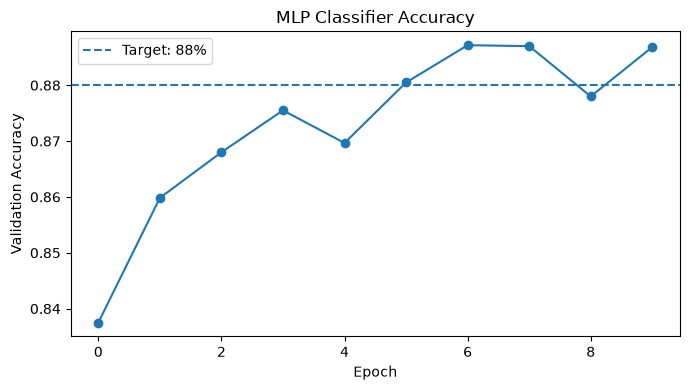

In [16]:

class MLPClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 256)
        self.fc2 = nn.Linear(256, 64)
        self.fc3 = nn.Linear(64, 10)

    def encode(self, x):
        x = x.view(x.size(0), -1)
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        return h2

    def forward(self, x):
        x = x.view(x.size(0), -1)
        h1 = F.relu(self.fc1(x))
        h2 = F.relu(self.fc2(h1))
        return self.fc3(h2)



classifier = MLPClassifier().to(device)
classifier_optimizer = torch.optim.Adam(
    classifier.parameters(),
    lr=1e-3
)

classifier_history = {
    "train_loss": [],
    "val_accuracy": []
}

CLASSIFIER_EPOCHS = 10
best_val_accuracy = 0.0
best_classifier_state = None

start_time = time.time()

for epoch in range(CLASSIFIER_EPOCHS):
    classifier.train()
    total_loss = 0.0
    total_samples = 0

    for x, y in train_loader:
        x, y = x.to(device), y.to(device)

        logits = classifier(x)
        loss = F.cross_entropy(logits, y)

        classifier_optimizer.zero_grad()
        loss.backward()
        classifier_optimizer.step()

        total_loss += loss.item() * x.size(0)
        total_samples += x.size(0)

    train_loss = total_loss / total_samples
    classifier_history["train_loss"].append(train_loss)

    classifier.eval()
    correct, total = 0, 0

    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(device), y.to(device)

            predictions = classifier(x).argmax(dim=1)
            correct += (predictions == y).sum().item()
            total += y.size(0)

    val_acc = correct / total
    classifier_history["val_accuracy"].append(val_acc)

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        best_classifier_state = copy.deepcopy(
            classifier.state_dict()
        )

        torch.save(
            best_classifier_state,
            f"{OUTPUT_DIR}/mlp_classifier_best.pth"
        )

    print(
        f"Epoch {epoch+1}/{CLASSIFIER_EPOCHS} | "
        f"Loss: {train_loss:.4f} | "
        f"Val accuracy: {val_acc:.2%} | "
        f"Best: {best_val_accuracy:.2%}"
    )

classifier.load_state_dict(best_classifier_state)

print(
    f"Training time: {(time.time() - start_time) / 60:.2f} minutes"
)
print(f"Best validation accuracy: {best_val_accuracy:.2%}")

torch.save(
    classifier.state_dict(),
    f"{OUTPUT_DIR}/mlp_classifier.pth"
)

plt.figure(figsize=(7, 4))
plt.plot(classifier_history["val_accuracy"], marker="o")
plt.axhline(0.88, linestyle="--", label="Target: 88%")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("MLP Classifier Accuracy")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/classifier_accuracy.png", dpi=150)
plt.show()


## Test Set Evaluation Classifier

In [17]:

classifier.eval()
test_correct, test_total = 0, 0
all_predictions, all_labels = [], []

with torch.no_grad():
    for x, y in test_loader:
        x, y = x.to(device), y.to(device)
        logits = classifier(x)
        pred = logits.argmax(dim=1)

        test_correct += (pred == y).sum().item()
        test_total += y.size(0)

        all_predictions.extend(pred.cpu().numpy())
        all_labels.extend(y.cpu().numpy())

test_accuracy = test_correct / test_total
print(f"MLP Classifier Test Accuracy: {test_accuracy:.2%}")

if test_accuracy < 0.88:
    print("Target 88% belum tercapai. Pertimbangkan menambah epoch atau tuning learning rate.")
else:
    print("Target akurasi 88% tercapai.")


MLP Classifier Test Accuracy: 87.95%
Target 88% belum tercapai. Pertimbangkan menambah epoch atau tuning learning rate.


Eksperimen 1: bobot classifier ditransposisikan menjadi gambar

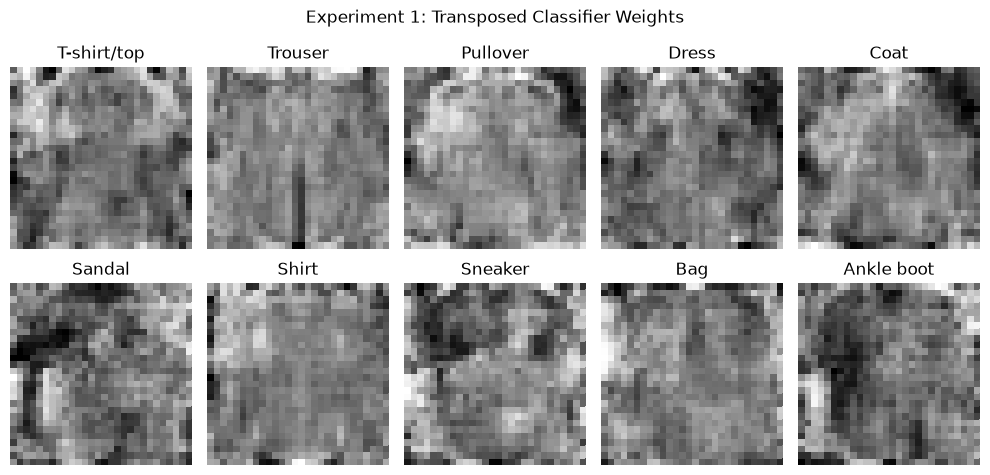

In [18]:

classifier.eval()

with torch.no_grad():
    class_one_hot = torch.eye(10, device=device)

    # Reverse projection through transposed classifier weights.
    h2 = class_one_hot @ classifier.fc3.weight
    h1 = h2 @ classifier.fc2.weight
    reconstructed = torch.sigmoid(h1 @ classifier.fc1.weight)
    class_weight_images = reconstructed.view(10, 1, 28, 28).cpu()

fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(class_weight_images[i, 0], cmap="gray")
    ax.set_title(classes[i])
    ax.axis("off")

plt.suptitle("Experiment 1: Transposed Classifier Weights")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/exp1_transposed_weights.png", dpi=150)
plt.show()


Eksperimen 2: transpose latent features menjadi gambar

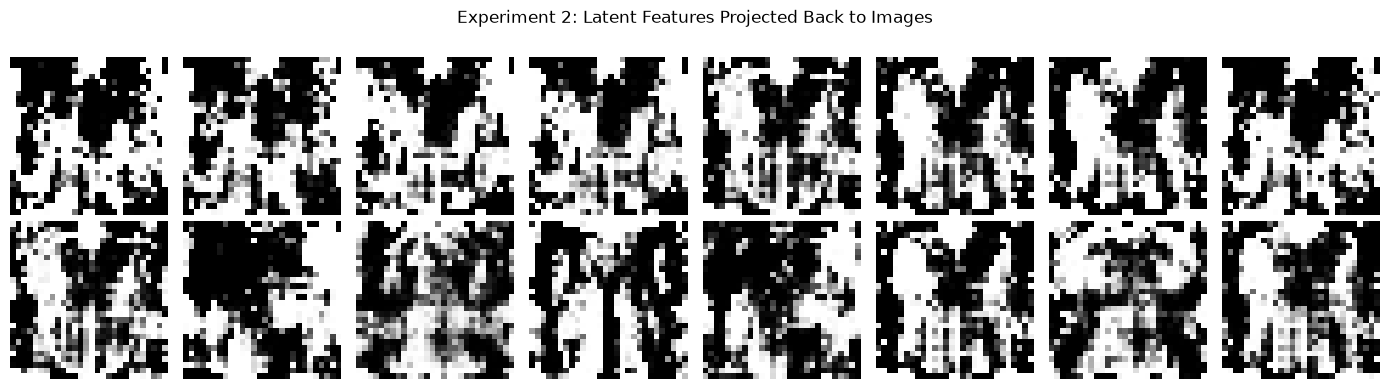

In [19]:

with torch.no_grad():
    x_batch, y_batch = next(iter(test_loader))
    x_batch = x_batch.to(device)

    latent_features = classifier.encode(x_batch)

    approx_hidden = latent_features @ classifier.fc2.weight
    approx_images = torch.sigmoid(approx_hidden @ classifier.fc1.weight)
    approx_images = approx_images.view(-1, 1, 28, 28).cpu()

fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(approx_images[i, 0], cmap="gray")
    ax.axis("off")

plt.suptitle("Experiment 2: Latent Features Projected Back to Images")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/exp2_latent_transpose.png", dpi=150)
plt.show()


Eksperimen 3: freeze classifier, lalu latih decoder

In [20]:

for param in classifier.parameters():
    param.requires_grad = False
classifier.eval()


class ClassifierDecoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, z):
        return self.net(z).view(-1, 1, 28, 28)


classifier_decoder = ClassifierDecoder().to(device)
decoder_optimizer = torch.optim.Adam(classifier_decoder.parameters(), lr=1e-3)
DECODER_EPOCHS = 5
decoder_history = []

start_time = time.time()

for epoch in range(DECODER_EPOCHS):
    classifier_decoder.train()
    total_loss, total_samples = 0, 0

    for x, _ in train_loader:
        x = x.to(device)

        with torch.no_grad():
            z = classifier.encode(x)

        reconstruction = classifier_decoder(z)
        loss = F.mse_loss(reconstruction, x)

        decoder_optimizer.zero_grad()
        loss.backward()
        decoder_optimizer.step()

        total_loss += loss.item() * x.size(0)
        total_samples += x.size(0)

    epoch_loss = total_loss / total_samples
    decoder_history.append(epoch_loss)
    print(f"Frozen-classifier decoder Epoch {epoch+1}/{DECODER_EPOCHS} | MSE: {epoch_loss:.5f}")

print(f"Decoder training time: {(time.time()-start_time)/60:.2f} minutes")
torch.save(classifier_decoder.state_dict(), f"{OUTPUT_DIR}/classifier_decoder.pth")


Frozen-classifier decoder Epoch 1/5 | MSE: 0.03742
Frozen-classifier decoder Epoch 2/5 | MSE: 0.02442
Frozen-classifier decoder Epoch 3/5 | MSE: 0.02216
Frozen-classifier decoder Epoch 4/5 | MSE: 0.02105
Frozen-classifier decoder Epoch 5/5 | MSE: 0.02027
Decoder training time: 0.96 minutes


Bandingkan classifier decoder dengan Autoencoder

Available model keys: ['Vanilla AE', 'Sparse AE', 'VAE']


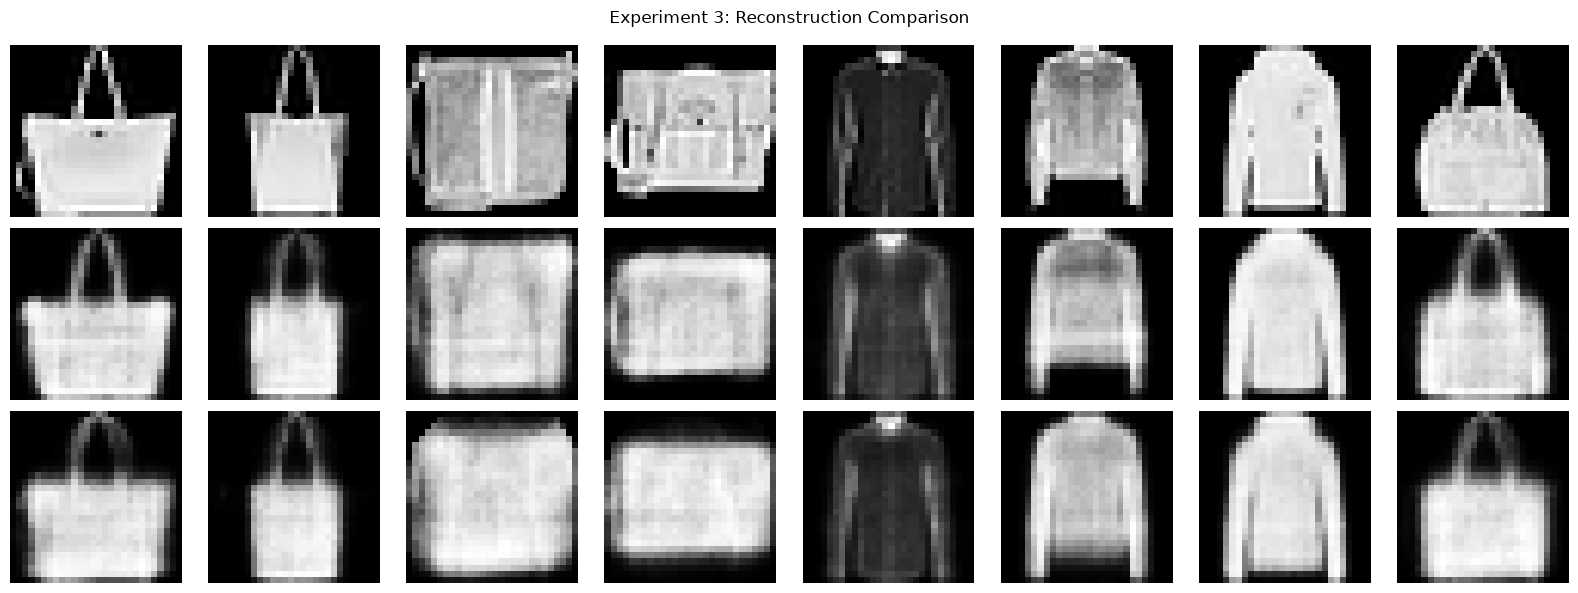

In [21]:

@torch.no_grad()
def compare_decoder_and_ae(n=8):
    classifier.eval()
    classifier_decoder.eval()

    print("Available model keys:", list(models.keys()))

    ae_key = next(
        (key for key in models if key.lower() in ["vanilla_ae", "ae", "vanilla ae"]),
        None
    )

    if ae_key is None:
        raise KeyError(
            f"Vanilla AE tidak ditemukan. Model yang tersedia: {list(models.keys())}"
        )

    ae_model = models[ae_key]
    ae_model.eval()

    x, _ = next(iter(test_loader))
    x = x[:n].to(device)

    classifier_z = classifier.encode(x)
    classifier_recon = classifier_decoder(classifier_z)

    ae_recon = ae_model(x)

    fig, axes = plt.subplots(3, n, figsize=(2 * n, 6))

    for i in range(n):
        axes[0, i].imshow(x[i, 0].cpu(), cmap="gray")
        axes[1, i].imshow(ae_recon[i, 0].cpu(), cmap="gray")
        axes[2, i].imshow(classifier_recon[i, 0].cpu(), cmap="gray")

        for r in range(3):
            axes[r, i].axis("off")

    axes[0, 0].set_ylabel("Original")
    axes[1, 0].set_ylabel("Vanilla AE")
    axes[2, 0].set_ylabel("Classifier Decoder")

    plt.suptitle("Experiment 3: Reconstruction Comparison")
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/exp3_decoder_vs_ae.png", dpi=150)
    plt.show()


compare_decoder_and_ae()


Eksperimen 4: random sampling dari distribusi laten empiris

Latent mean shape: (64,)
Latent std shape: (64,)


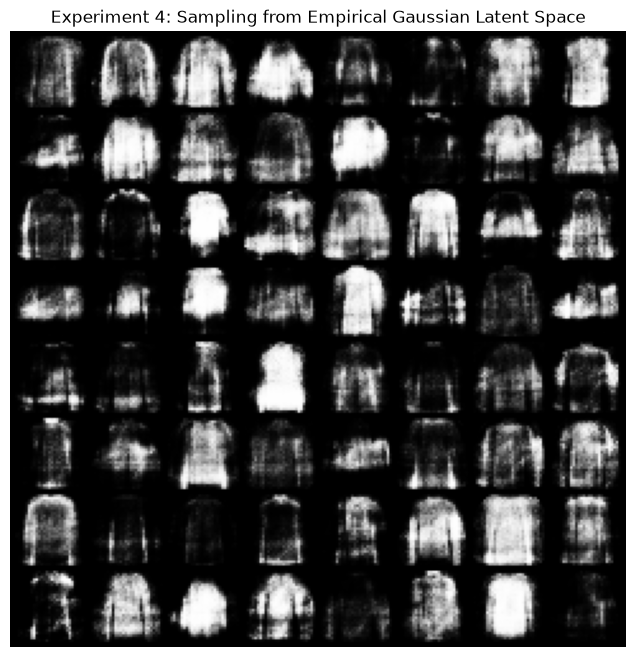

In [22]:

classifier.eval()
latent_batches = []

with torch.no_grad():
    for x, _ in train_loader:
        x = x.to(device)
        latent_batches.append(classifier.encode(x).cpu())

all_latents = torch.cat(latent_batches, dim=0)
latent_mean = all_latents.mean(dim=0)
latent_std = all_latents.std(dim=0).clamp(min=1e-6)

print("Latent mean shape:", tuple(latent_mean.shape))
print("Latent std shape:", tuple(latent_std.shape))

with torch.no_grad():
    sampled_z = latent_mean + latent_std * torch.randn(64, 64)
    sampled_z = sampled_z.to(device)
    random_generated = classifier_decoder(sampled_z).cpu()

grid = utils.make_grid(random_generated, nrow=8, padding=2)
plt.figure(figsize=(8, 8))
plt.imshow(grid.permute(1, 2, 0).squeeze(), cmap="gray")
plt.title("Experiment 4: Sampling from Empirical Gaussian Latent Space")
plt.axis("off")
plt.savefig(f"{OUTPUT_DIR}/exp4_latent_sampling.png", dpi=150, bbox_inches="tight")
plt.show()


Eksperimen 5: interpolasi di latent space

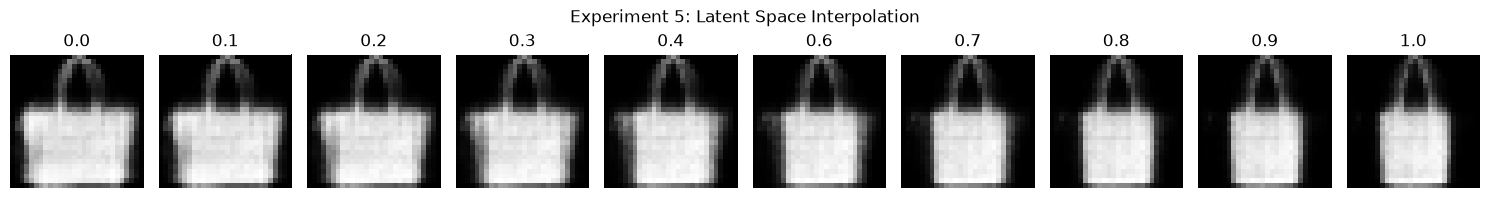

In [23]:

classifier.eval()
classifier_decoder.eval()

with torch.no_grad():
    x, _ = next(iter(test_loader))
    x = x[:2].to(device)
    z1, z2 = classifier.encode(x)

    alphas_interp = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    interpolated_z = (1 - alphas_interp) * z1 + alphas_interp * z2
    interpolated_images = classifier_decoder(interpolated_z).cpu()

fig, axes = plt.subplots(1, 10, figsize=(15, 2))
for i, ax in enumerate(axes):
    ax.imshow(interpolated_images[i, 0], cmap="gray")
    ax.set_title(f"{i/9:.1f}")
    ax.axis("off")

plt.suptitle("Experiment 5: Latent Space Interpolation")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/latent_interpolation.png", dpi=150)
plt.show()


## Final Evaluation

Hitung MSE, PSNR, SSIM, dan inference latency

In [24]:

@torch.no_grad()
def calculate_ssim_simple(x, y):
    mu_x = F.avg_pool2d(x, kernel_size=7, stride=1, padding=3)
    mu_y = F.avg_pool2d(y, kernel_size=7, stride=1, padding=3)

    sigma_x = F.avg_pool2d(x * x, 7, 1, 3) - mu_x * mu_x
    sigma_y = F.avg_pool2d(y * y, 7, 1, 3) - mu_y * mu_y
    sigma_xy = F.avg_pool2d(x * y, 7, 1, 3) - mu_x * mu_y

    c1, c2 = 0.01**2, 0.03**2
    numerator = (2 * mu_x * mu_y + c1) * (2 * sigma_xy + c2)
    denominator = (
        (mu_x**2 + mu_y**2 + c1) *
        (sigma_x + sigma_y + c2)
    )

    return (numerator / (denominator + 1e-8)).mean().item()


@torch.no_grad()
def evaluate_reconstruction(model, loader, model_name):
    model.eval()
    mse_sum, ssim_sum, count = 0.0, 0.0, 0
    total_latency = 0.0
    measured_batches = 0

    for x, _ in loader:
        x = x.to(device)

        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()

        if model_name == "VAE":
            recon, _, _ = model(x)
        else:
            recon = model(x)

        if device.type == "cuda":
            torch.cuda.synchronize()
        total_latency += time.perf_counter() - t0
        measured_batches += 1

        mse = F.mse_loss(
            recon, x, reduction="none"
        ).flatten(1).mean(1)

        batch_size = x.size(0)
        mse_sum += mse.sum().item()
        ssim_sum += calculate_ssim_simple(
            x, recon.clamp(0, 1)
        ) * batch_size
        count += batch_size

    avg_mse = mse_sum / count
    avg_psnr = 10 * np.log10(1.0 / max(avg_mse, 1e-12))
    avg_ssim = ssim_sum / count
    latency_ms = 1000 * total_latency / max(measured_batches, 1)

    return {
        "Model": model_name,
        "MSE": avg_mse,
        "PSNR_dB": avg_psnr,
        "SSIM_approx": avg_ssim,
        "Latency_ms_per_batch": latency_ms
    }


# Automatically find model keys, ignoring capitalization and spaces.
def find_model_key(possible_names):
    normalized = {
        key.lower().replace("_", "").replace(" ", ""): key
        for key in models.keys()
    }

    for name in possible_names:
        normalized_name = name.lower().replace("_", "").replace(" ", "")
        if normalized_name in normalized:
            return models[normalized[normalized_name]]

    raise KeyError(
        f"Model not found. Available keys: {list(models.keys())}"
    )


reconstruction_models = [
    ("Vanilla AE", find_model_key(["vanilla_ae", "AE", "VanillaAE"]), "AE"),
    ("Sparse AE", find_model_key(["sparse_ae", "SparseAE"]), "AE"),
    ("VAE", find_model_key(["vae", "VAE"]), "VAE")
]

evaluation_results = []

for name, model, kind in reconstruction_models:
    result = evaluate_reconstruction(model, test_loader, kind)
    result["Model"] = name
    evaluation_results.append(result)

import pandas as pd

metrics_df = pd.DataFrame(evaluation_results)
display(metrics_df.round(4))

metrics_df.to_csv(
    f"{OUTPUT_DIR}/reconstruction_metrics.csv",
    index=False
)


,Model,MSE,PSNR_dB,SSIM_approx,Latency_ms_per_batch
0,Vanilla AE,0.0117,19.3291,0.7673,4.9335
1,Sparse AE,0.0117,19.3269,0.7658,3.9136
2,VAE,0.0200,16.9947,0.6775,3.5332


Perbandingan training loss dan hasil eksperimen

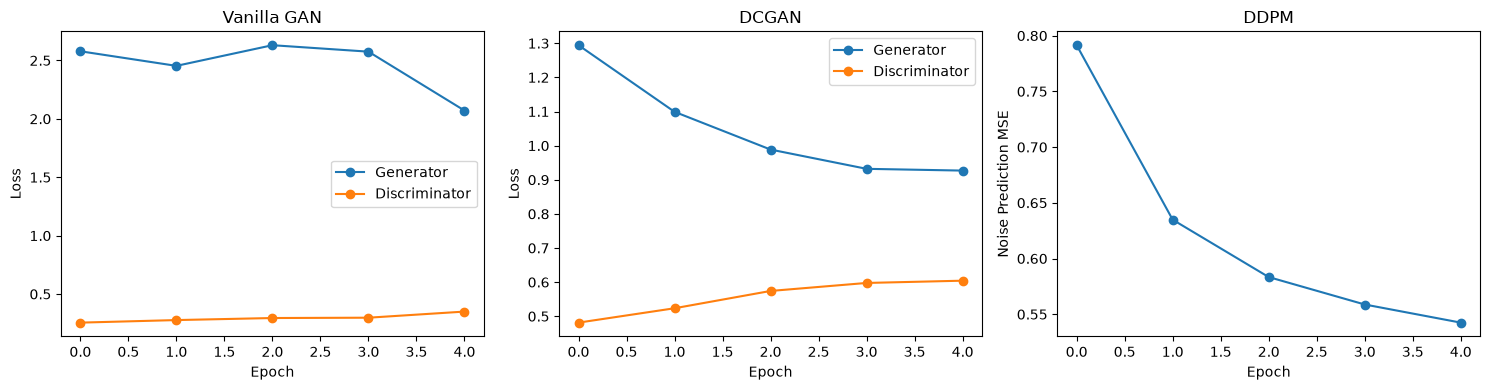

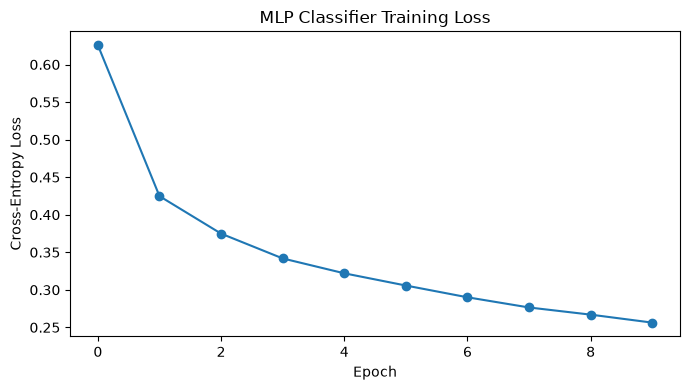

In [25]:

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(gan_history["G"], marker="o", label="Generator")
axes[0].plot(gan_history["D"], marker="o", label="Discriminator")
axes[0].set_title("Vanilla GAN")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(dc_history["G"], marker="o", label="Generator")
axes[1].plot(dc_history["D"], marker="o", label="Discriminator")
axes[1].set_title("DCGAN")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

axes[2].plot(ddpm_history, marker="o")
axes[2].set_title("DDPM")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Noise Prediction MSE")

plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/generative_training_comparison.png", dpi=150)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(classifier_history["train_loss"], marker="o")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("MLP Classifier Training Loss")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/classifier_training_loss.png", dpi=150)
plt.show()


In [26]:
print("=== CLASSIFIER CHECK ===")

for name, obj in globals().copy().items():
    if any(k in name.lower() for k in [
        "classifier", "class_model", "class_loader",
        "class_history", "test_acc", "accuracy"
    ]):
        try:
            print(name, "=", obj if isinstance(
                obj, (int, float, str, dict, list, tuple
                )) else type(obj).__name__)
        except Exception:
            pass

=== CLASSIFIER CHECK ===
MLPClassifier = type
classifier = MLPClassifier
classifier_optimizer = Adam
classifier_history = {'train_loss': [0.6256947325865427, 0.42473361202081045, 0.37483113225301107, 0.3418124177853266, 0.32200259828567507, 0.30572257113456724, 0.29006275526682535, 0.2765031465291977, 0.2669691954056422, 0.25633905601501467], 'val_accuracy': [0.8375, 0.8598333333333333, 0.868, 0.8755, 0.8696666666666667, 0.8805, 0.8871666666666667, 0.887, 0.878, 0.8868333333333334]}
CLASSIFIER_EPOCHS = 10
best_val_accuracy = 0.8871666666666667
best_classifier_state = OrderedDict({'fc1.weight': tensor([[ 0.0966, -0.1079, -0.1021,  ...,  0.1458,  0.0259,  0.1597],
        [-0.0267,  0.0674,  0.0513,  ...,  0.0402, -0.0095, -0.0091],
        [-0.0120, -0.1223, -0.1995,  ..., -0.0483,  0.0251, -0.0346],
        ...,
        [ 0.1132, -0.0388, -0.1704,  ...,  0.0927,  0.1313,  0.0202],
        [ 0.1052,  0.1070,  0.1545,  ...,  0.0993, -0.0031,  0.0546],
        [ 0.0456,  0.1047,  0.0219, 

Summary hasil eksperimen

In [27]:
%pip install -q torchmetrics torch-fidelity

import pandas as pd
from torchmetrics.image.fid import FrechetInceptionDistance

N_FID = len(test_dataset)      # 6000 gambar real (test set) vs 6000 gambar fake
FID_BATCH = 100                # aman untuk VRAM 4 GB
DDPM_FID_BATCH = 500           # sampler DDPM cuma MLP, jadi batch besar aman

torch.manual_seed(SEED)

# Statistik real dihitung sekali saja, tidak ikut ke-reset saat fid.reset()
fid = FrechetInceptionDistance(
    feature=2048,
    normalize=True,            # input float di rentang [0, 1]
    reset_real_features=False
).to(device)


def to_rgb(x):
    """Fashion-MNIST [N,1,28,28] -> [N,3,28,28], rentang [0,1]."""
    return x.clamp(0, 1).repeat(1, 3, 1, 1)


# 1) Statistik gambar real (test set)
fid.reset()
with torch.no_grad():
    for x, _ in test_loader:
        fid.update(to_rgb(x.to(device)), real=True)
print(f"Real images processed: {N_FID}")


@torch.no_grad()
def fid_from_reconstruction(model, kind):
    """FID untuk model reconstruction (AE / Sparse AE / VAE) pada test set."""
    model.eval()
    fid.reset()
    for x, _ in test_loader:
        x = x.to(device)
        recon = model(x)[0] if kind == "VAE" else model(x)
        fid.update(to_rgb(recon), real=False)
    return fid.compute().item()


@torch.no_grad()
def fid_from_sampler(sample_fn, n=N_FID, batch_size=FID_BATCH):
    """FID untuk model generatif. sample_fn(b) -> tensor [b,1,28,28]."""
    fid.reset()
    done = 0
    while done < n:
        b = min(batch_size, n - done)
        fid.update(to_rgb(sample_fn(b)), real=False)
        done += b
    return fid.compute().item()


fid_results = {}

# 2) Autoencoder family (FID dari hasil rekonstruksi test set)
for name, kind in [("Vanilla AE", "AE"), ("Sparse AE", "AE"), ("VAE", "VAE")]:
    fid_results[name] = fid_from_reconstruction(models[name], kind)
    print(f"{name:<30} FID: {fid_results[name]:.2f}")

# 3) VAE sebagai generator (sampling dari prior N(0, I))
models["VAE"].eval()
fid_results["VAE (sampling prior)"] = fid_from_sampler(
    lambda b: models["VAE"].decode(torch.randn(b, LATENT_DIM, device=device))
)
print(f"{'VAE (sampling prior)':<30} FID: {fid_results['VAE (sampling prior)']:.2f}")

# 4) Vanilla GAN
gan_G.eval()
fid_results["Vanilla GAN"] = fid_from_sampler(
    lambda b: gan_G(torch.randn(b, NOISE_DIM, device=device))
)
print(f"{'Vanilla GAN':<30} FID: {fid_results['Vanilla GAN']:.2f}")

# 5) DCGAN
dc_G.eval()
fid_results["DCGAN"] = fid_from_sampler(
    lambda b: dc_G(torch.randn(b, NOISE_DIM, device=device))
)
print(f"{'DCGAN':<30} FID: {fid_results['DCGAN']:.2f}")

# 6) DDPM (pakai fungsi sample_ddpm yang sudah ada)
fid_results["DDPM"] = fid_from_sampler(
    lambda b: sample_ddpm(b), batch_size=DDPM_FID_BATCH
)
print(f"{'DDPM':<30} FID: {fid_results['DDPM']:.2f}")

# 7) Simpan hasil
fid_df = pd.DataFrame(
    [{"Model": k, "FID": v} for k, v in fid_results.items()]
)
display(fid_df.round(2))
fid_df.to_csv(f"{OUTPUT_DIR}/fid_scores.csv", index=False)

# Gabungkan ke metrics_df (kalau sudah ada) dan experiment_summary.json
if "metrics_df" in globals():
    metrics_df["FID"] = metrics_df["Model"].map(fid_results)
    metrics_df.to_csv(f"{OUTPUT_DIR}/reconstruction_metrics.csv", index=False)
    display(metrics_df.round(4))

if "summary" in globals():
    summary["fid_scores"] = {k: float(v) for k, v in fid_results.items()}
    with open(f"{OUTPUT_DIR}/experiment_summary.json", "w") as f:
        json.dump(summary, f, indent=2)

if device.type == "cuda":
    torch.cuda.empty_cache()

print("FID selesai. Hasil disimpan di:", os.path.abspath(OUTPUT_DIR))


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to C:\Users\ASUS/.cache\torch\hub\checkpoints\weights-inception-2015-12-05-6726825d.pth
100.0%


Real images processed: 6000
Vanilla AE                     FID: 59.51
Sparse AE                      FID: 58.23
VAE                            FID: 81.76
VAE (sampling prior)           FID: 127.03
Vanilla GAN                    FID: 249.35
DCGAN                          FID: 62.05


KeyboardInterrupt: 

In [29]:

import pandas as pd

LAT_BATCH = 64       # ukuran batch yang diukur (ms/batch)
LAT_WARMUP = 10      # iterasi pemanasan, tidak dihitung
LAT_RUNS = 50        # iterasi yang dihitung (DDPM otomatis dikurangi)

def sync():
    if device.type == "cuda":
        torch.cuda.synchronize()

@torch.no_grad()
def measure_latency_ms(fn, warmup=LAT_WARMUP, runs=LAT_RUNS):
    for _ in range(warmup):
        fn()
    sync()
    times = []
    for _ in range(runs):
        t0 = time.perf_counter()
        fn()
        sync()
        times.append((time.perf_counter() - t0) * 1000)
    return float(np.mean(times)), float(np.std(times))

gan_G.eval()
dc_G.eval()
models["VAE"].eval()
ddpm.eval()

latency_targets = [
    ("Vanilla GAN",   lambda: gan_G(torch.randn(LAT_BATCH, NOISE_DIM, device=device)),               1),
    ("DCGAN",         lambda: dc_G(torch.randn(LAT_BATCH, NOISE_DIM, device=device)),                1),
    ("VAE (decoder)", lambda: models["VAE"].decode(torch.randn(LAT_BATCH, LATENT_DIM, device=device)), 1),
    ("DDPM",          lambda: sample_ddpm(LAT_BATCH),                                                DIFFUSION_STEPS),
]

latency_rows = []
for name, fn, passes in latency_targets:
    is_ddpm = (name == "DDPM")
    mean_ms, std_ms = measure_latency_ms(
        fn,
        warmup=3 if is_ddpm else LAT_WARMUP,
        runs=10 if is_ddpm else LAT_RUNS
    )
    latency_rows.append({
        "Model": name,
        "Latensi (ms/batch)": round(mean_ms, 3),
        "Std (ms)": round(std_ms, 3),
        "Jumlah forward pass": passes
    })
    print(f"{name:<15} {mean_ms:8.3f} ms/batch (±{std_ms:.3f}) | forward pass: {passes}")

latency_df = pd.DataFrame(latency_rows)
display(latency_df)
latency_df.to_csv(f"{OUTPUT_DIR}/sampling_latency.csv", index=False)

if "summary" in globals():
    summary["sampling_latency"] = latency_rows
    with open(f"{OUTPUT_DIR}/experiment_summary.json", "w") as f:
        json.dump(summary, f, indent=2)

Vanilla GAN        3.506 ms/batch (±2.062) | forward pass: 1
DCGAN             13.286 ms/batch (±0.952) | forward pass: 1
VAE (decoder)      0.687 ms/batch (±0.184) | forward pass: 1
DDPM             192.776 ms/batch (±30.159) | forward pass: 100


,Model,Latensi (ms/batch),Std (ms),Jumlah forward pass
0,Vanilla GAN,3.506,2.062,1
1,DCGAN,13.286,0.952,1
2,VAE (decoder),0.687,0.184,1
3,DDPM,192.776,30.159,100


In [28]:

summary = {
    "dataset": "Fashion-MNIST",
    "seed": SEED,
    "device": str(device),
    "batch_size": BATCH_SIZE,
    "latent_dim": LATENT_DIM,
    "classifier_test_accuracy": float(test_accuracy),
    "classifier_target_88_percent_reached": bool(test_accuracy >= 0.88),
    "vanilla_gan_final_generator_loss": float(gan_history["G"][-1]),
    "vanilla_gan_final_discriminator_loss": float(gan_history["D"][-1]),
    "dcgan_final_generator_loss": float(dc_history["G"][-1]),
    "dcgan_final_discriminator_loss": float(dc_history["D"][-1]),
    "ddpm_final_noise_mse": float(ddpm_history[-1]),
    "reconstruction_metrics": evaluation_results
}

with open(f"{OUTPUT_DIR}/experiment_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Eksperimen selesai.")
print(f"Semua hasil disimpan di: {os.path.abspath(OUTPUT_DIR)}")
print("Classifier test accuracy:", f"{test_accuracy:.2%}")



Eksperimen selesai.
Semua hasil disimpan di: c:\Users\ASUS\Downloads\DL_GenerativeModel\outputs
Classifier test accuracy: 87.95%
